# EP3 - PagoSeguro: Deteccion de fraude financiero

**Asignatura:** ITY1102 - Arquitectura de Sistemas de Inteligencia Artificial  
**Caso:** 3 - Deteccion de Fraude Financiero  
**Modelo:** XGBoost con calibracion de probabilidades  
**Dataset:** Credit Card Fraud Detection (`mlg-ulb/creditcardfraud`)

## Objetivo

Construir y evaluar un modelo que estime si una transaccion es fraudulenta. El notebook descarga los datos desde Kaggle usando KaggleHub, prepara los datos, entrena XGBoost, calibra sus probabilidades con un conjunto separado y selecciona un umbral usando validacion.

La seleccion del umbral busca cumplir un FPR maximo de 5%, mantener un recall minimo experimental de 80% y maximizar F0.5, una metrica que da mas importancia a la precision. Al final se evalua una sola vez con el conjunto de prueba, se generan explicaciones SHAP y se guardan los archivos necesarios para continuar con FastAPI y AWS SageMaker.

**Importante:** el umbral y las metricas definitivas se calculan al ejecutar el notebook. No se deben reemplazar por resultados estimados.

## 1. Instalacion de librerias

In [ ]:
%pip install -q kagglehub pandas numpy matplotlib seaborn scikit-learn xgboost shap joblib

## 2. Importacion de librerias y configuracion

In [ ]:
import json
import os
import warnings
from pathlib import Path

import kagglehub
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.20
CALIBRATION_SIZE = 0.10  # porcentaje del total, reservado para calibrar probabilidades
VALIDATION_SIZE = 0.10   # porcentaje del total, reservado para elegir el umbral
MAX_FPR = 0.05           # maximo experimental de falsos positivos sobre transacciones legitimas
MIN_RECALL = 0.80        # minimo experimental de fraudes que se busca detectar
F_BETA = 0.5             # beta menor que 1 da mas peso a la precision

ARTIFACT_DIR = Path("artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

print("Version de XGBoost:", xgb.__version__)
print("Version de SHAP:", shap.__version__)
print("Carpeta de salida:", ARTIFACT_DIR.resolve())

Version de XGBoost: 3.4.1
Version de SHAP: 0.54.1
Carpeta de salida: /content/artifacts


## 3. Descarga del dataset desde Kaggle

In [ ]:
# Descargar la ultima version disponible del dataset
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

print("Dataset descargado en:", path)

# Buscar el archivo CSV dentro de la carpeta descargada
csv_files = list(Path(path).rglob("creditcard.csv"))

if not csv_files:
    raise FileNotFoundError(
        "No se encontro creditcard.csv. Revisa que KaggleHub haya descargado el dataset correctamente."
    )

DATASET_PATH = csv_files[0]
print("Archivo encontrado:", DATASET_PATH)

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset descargado en: /kaggle/input/creditcardfraud
Archivo encontrado: /kaggle/input/creditcardfraud/creditcard.csv


## 4. Carga y revision inicial

In [ ]:
df = pd.read_csv(DATASET_PATH)

required_columns = {"Time", "Amount", "Class"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"Faltan columnas requeridas en el dataset: {missing_columns}")

print("Dimensiones del dataset:", df.shape)
print("Columnas:", list(df.columns))
display(df.head())

print("\\nTipos de datos:")
print(df.dtypes)

print("\\nValores nulos:", int(df.isnull().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))

print("\\nDistribucion de la variable Class:")
print(df["Class"].value_counts().rename(index={0: "Legitima", 1: "Fraude"}))

Dimensiones del dataset: (284807, 31)
Columnas: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


\nTipos de datos:
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object
\nValores nulos: 0
Filas duplicadas: 1081
\nDistribucion de la variable Class:
Class
Legitima    284315
Fraude         492
Name: count, dtype: int64


## 5. Analisis exploratorio de datos

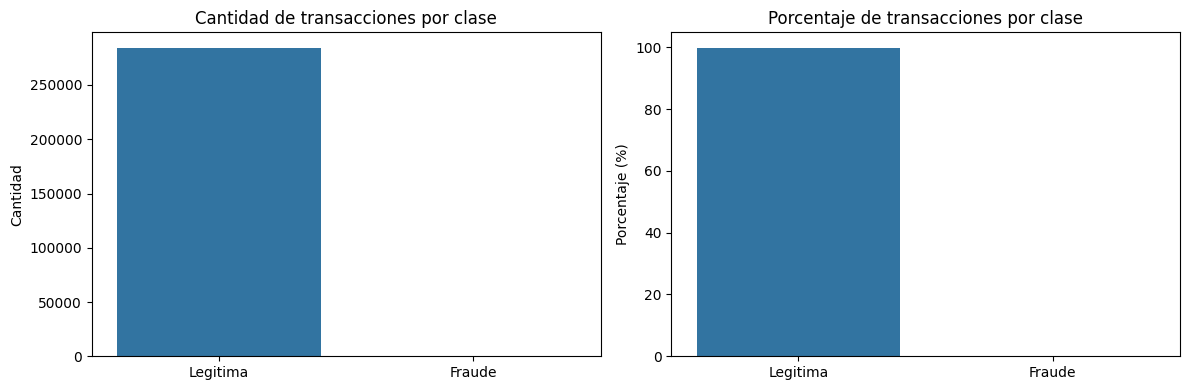

Porcentaje de fraude: 0.1727%
Porcentaje de transacciones legitimas: 99.8273%


In [ ]:
# Distribucion de clases
class_counts = df["Class"].value_counts().sort_index()
class_percent = df["Class"].value_counts(normalize=True).sort_index() * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=["Legitima", "Fraude"], y=class_counts.values, ax=axes[0])
axes[0].set_title("Cantidad de transacciones por clase")
axes[0].set_ylabel("Cantidad")

sns.barplot(x=["Legitima", "Fraude"], y=class_percent.values, ax=axes[1])
axes[1].set_title("Porcentaje de transacciones por clase")
axes[1].set_ylabel("Porcentaje (%)")
plt.tight_layout()
plt.show()

print("Porcentaje de fraude: {:.4f}%".format(class_percent.loc[1]))
print("Porcentaje de transacciones legitimas: {:.4f}%".format(class_percent.loc[0]))

,count,mean,median,min,max
Legitima,284315,88.291022,22.00,0.0,25691.16
Fraude,492,122.211321,9.25,0.0,2125.87


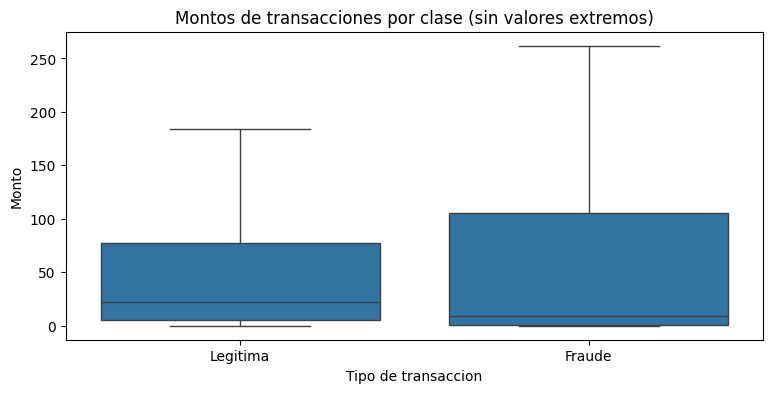

In [ ]:
# Resumen del monto segun el tipo de transaccion
amount_summary = df.groupby("Class")["Amount"].agg(["count", "mean", "median", "min", "max"])
amount_summary.index = ["Legitima", "Fraude"]
display(amount_summary)

plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="Class", y="Amount", showfliers=False)
plt.xticks([0, 1], ["Legitima", "Fraude"])
plt.title("Montos de transacciones por clase (sin valores extremos)")
plt.xlabel("Tipo de transaccion")
plt.ylabel("Monto")
plt.show()

### Observacion sobre el desbalance

El dataset tiene muchas mas transacciones legitimas que fraudulentas. Por eso, la accuracy no debe analizarse sola: un modelo podria acertar la mayoria de las transacciones simplemente prediciendo la clase legitima. Para este problema tambien revisaremos precision, recall, F1-score, FPR y la matriz de confusion.

## 6. Preparacion de los datos

In [ ]:
# Definir variables predictoras (X), objetivo (y) y nombres de caracteristicas a partir del DataFrame cargado
FEATURE_NAMES = [col for col in df.columns if col not in ["Time", "Class"]]
X = df[FEATURE_NAMES]
y = df["Class"]

# Separar primero el conjunto de prueba (20%). Este conjunto se reserva hasta la evaluacion final.
X_train_cal_val, X_test, y_train_cal_val, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

# Reservar 10% para calibracion y 10% para seleccion del umbral.
# El conjunto de entrenamiento queda con aproximadamente 60% de los datos.
cal_val_relative_size = (CALIBRATION_SIZE + VALIDATION_SIZE) / (1 - TEST_SIZE)
X_train, X_cal_val, y_train, y_cal_val = train_test_split(
    X_train_cal_val,
    y_train_cal_val,
    test_size=cal_val_relative_size,
    stratify=y_train_cal_val,
    random_state=RANDOM_STATE,
)

# Separar calibracion y validacion. Ninguno de estos datos se usa para entrenar XGBoost.
validation_relative_size = VALIDATION_SIZE / (CALIBRATION_SIZE + VALIDATION_SIZE)
X_cal, X_val, y_cal, y_val = train_test_split(
    X_cal_val,
    y_cal_val,
    test_size=validation_relative_size,
    stratify=y_cal_val,
    random_state=RANDOM_STATE,
)

print("Entrenamiento:", X_train.shape, "| Fraudes:", int(y_train.sum()))
print("Calibracion:", X_cal.shape, "| Fraudes:", int(y_cal.sum()))
print("Validacion:", X_val.shape, "| Fraudes:", int(y_val.sum()))
print("Prueba:", X_test.shape, "| Fraudes:", int(y_test.sum()))

# Verificar que no existan valores nulos en las variables del modelo.
if X_train.isnull().sum().sum() > 0:
    raise ValueError("Hay valores nulos en los datos de entrenamiento. Se debe revisar su tratamiento.")

print("\nCantidad de variables predictoras:", len(FEATURE_NAMES))

Entrenamiento: (170883, 29) | Fraudes: 295
Calibracion: (28481, 29) | Fraudes: 50
Validacion: (28481, 29) | Fraudes: 49
Prueba: (56962, 29) | Fraudes: 98

Cantidad de variables predictoras: 29


## 7. Entrenamiento del modelo XGBoost

Se utiliza `scale_pos_weight` para dar mayor peso a la clase minoritaria durante el entrenamiento. Este valor se calcula solamente con los datos de entrenamiento.

Los hiperparametros principales son:

- `n_estimators`: cantidad de arboles.
- `max_depth`: profundidad maxima de cada arbol.
- `learning_rate`: aporte de cada arbol al resultado.
- `subsample` y `colsample_bytree`: fraccion de filas y variables usadas por arbol.
- `scale_pos_weight`: peso adicional para la clase fraude.

In [ ]:
# Peso de la clase positiva calculado solo con entrenamiento
negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / max(positive_count, 1)

print("scale_pos_weight:", round(scale_pos_weight, 2))

model = xgb.XGBClassifier(
    objective="binary:logistic",
    n_estimators=400,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=1,
    reg_lambda=5,
    scale_pos_weight=scale_pos_weight,
    eval_metric="aucpr",
    tree_method="hist",
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

model.fit(X_train, y_train)
print("Entrenamiento terminado")

scale_pos_weight: 578.26
Entrenamiento terminado


## 8. Calibracion de probabilidades

XGBoost puede entregar probabilidades que no representan directamente la frecuencia real de fraude, especialmente porque se utiliza `scale_pos_weight` para tratar el desbalance de clases.

Para mejorar su interpretacion se aplica una calibracion sigmoid (Platt scaling). El modelo base se entrena solo con entrenamiento; el calibrador aprende usando el conjunto de calibracion; y el umbral se selecciona con un conjunto de validacion distinto. El conjunto de prueba permanece separado.

La calibracion no mejora por si sola la capacidad de ordenar las transacciones. Su objetivo es que las probabilidades sean mas interpretables. Si la calibracion empeora el Brier Score en validacion o aprende una relacion inversa, el notebook conserva las probabilidades originales.

Se aplicara calibracion sigmoid (Platt scaling).
Brier Score original en validacion: 0.000490
Brier Score final en validacion: 0.000469
Metodo aplicado: Platt scaling


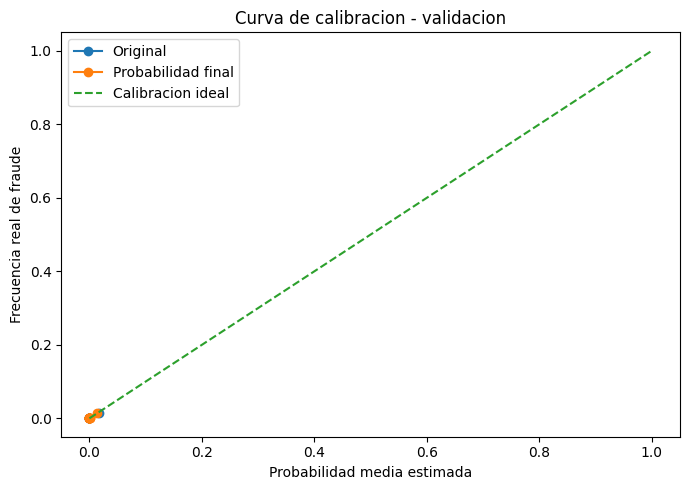

Coeficiente de calibracion: 0.6484389015728145


In [ ]:
def calculate_metrics(y_true, probabilities, threshold=0.5):
    """Calcula metricas de clasificacion usando un umbral indicado."""
    predictions = (np.asarray(probabilities) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, predictions, labels=[0, 1]).ravel()

    fpr = fp / (fp + tn) if (fp + tn) else 0.0
    fnr = fn / (fn + tp) if (fn + tp) else 0.0

    return {
        "threshold": float(threshold),
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1_score": f1_score(y_true, predictions, zero_division=0),
        "fpr": fpr,
        "fnr": fnr,
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
    }


def probabilities_to_logit(probabilities):
    """Transforma probabilidades a log-odds para aplicar calibracion sigmoid."""
    probabilities = np.asarray(probabilities, dtype=float)
    probabilities = np.clip(probabilities, 1e-6, 1 - 1e-6)
    return np.log(probabilities / (1 - probabilities)).reshape(-1, 1)


# Entrenar calibrador solo con el conjunto reservado para calibracion.
calibration_raw_probabilities = model.predict_proba(X_cal)[:, 1]
calibrator = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000)
calibrator.fit(probabilities_to_logit(calibration_raw_probabilities), y_cal)

# Comparar calibracion original y calibrada en validacion.
validation_raw_probabilities = model.predict_proba(X_val)[:, 1]
validation_calibrated_probabilities = calibrator.predict_proba(
    probabilities_to_logit(validation_raw_probabilities)
)[:, 1]

brier_raw_validation = brier_score_loss(y_val, validation_raw_probabilities)
brier_calibrated_validation = brier_score_loss(y_val, validation_calibrated_probabilities)
calibration_coefficient = float(calibrator.coef_[0, 0])

# Evitar usar una calibracion que empeore el Brier Score o invierta el orden del riesgo.
if calibration_coefficient <= 0 or brier_calibrated_validation >= brier_raw_validation:
    print("La calibracion no mejoro el Brier Score o aprendio una pendiente no positiva.")
    print("Se conservaran las probabilidades originales de XGBoost.")
    calibrator = None
    validation_probabilities = validation_raw_probabilities
else:
    print("Se aplicara calibracion sigmoid (Platt scaling).")
    validation_probabilities = validation_calibrated_probabilities


def calibrate_probabilities(raw_probabilities):
    """Aplica el calibrador guardado; si no se usa, devuelve la probabilidad original."""
    raw_probabilities = np.asarray(raw_probabilities, dtype=float)
    if calibrator is None:
        return raw_probabilities
    return calibrator.predict_proba(probabilities_to_logit(raw_probabilities))[:, 1]


brier_final_validation = brier_score_loss(y_val, validation_probabilities)
print("Brier Score original en validacion: {:.6f}".format(brier_raw_validation))
print("Brier Score final en validacion: {:.6f}".format(brier_final_validation))
print("Metodo aplicado:", "Platt scaling" if calibrator is not None else "Probabilidades originales")

# Curva de calibracion para observar si las probabilidades se acercan a las frecuencias reales.
frac_raw, mean_raw = calibration_curve(y_val, validation_raw_probabilities, n_bins=10, strategy="quantile")
frac_final, mean_final = calibration_curve(y_val, validation_probabilities, n_bins=10, strategy="quantile")

plt.figure(figsize=(7, 5))
plt.plot(mean_raw, frac_raw, marker="o", label="Original")
plt.plot(mean_final, frac_final, marker="o", label="Probabilidad final")
plt.plot([0, 1], [0, 1], linestyle="--", label="Calibracion ideal")
plt.title("Curva de calibracion - validacion")
plt.xlabel("Probabilidad media estimada")
plt.ylabel("Frecuencia real de fraude")
plt.legend()
plt.tight_layout()
plt.show()

print("Coeficiente de calibracion:", calibration_coefficient if calibrator is not None else "No aplicado")

## 9. Seleccion del umbral con validacion

Se busca un punto de operacion que cumpla dos condiciones experimentales: FPR maximo de 5% y recall minimo de 80%. Entre los umbrales que cumplen ambas condiciones se selecciona el que maximiza F0.5, metrica que da mas peso a la precision que al recall.

Como comparacion, tambien se calcula el umbral que maximiza recall bajo el mismo limite de FPR. Esto permite ver el costo de priorizar la deteccion por sobre la reduccion de falsas alarmas.

El umbral se elige solamente con validacion. No se ajusta mirando los resultados del conjunto de prueba.

In [ ]:
# Evaluar todos los umbrales de la curva ROC en el conjunto de validacion.
fpr_values, tpr_values, thresholds = roc_curve(
    y_val,
    validation_probabilities,
    drop_intermediate=False,
)

positive_count = int((np.asarray(y_val) == 1).sum())
negative_count = int((np.asarray(y_val) == 0).sum())
tp_values = tpr_values * positive_count
fp_values = fpr_values * negative_count
precision_values = np.divide(
    tp_values,
    tp_values + fp_values,
    out=np.zeros_like(tp_values, dtype=float),
    where=(tp_values + fp_values) > 0,
)

beta_squared = F_BETA ** 2
f_beta_values = np.divide(
    (1 + beta_squared) * precision_values * tpr_values,
    beta_squared * precision_values + tpr_values,
    out=np.zeros_like(precision_values, dtype=float),
    where=(beta_squared * precision_values + tpr_values) > 0,
)

# Umbrales que respetan el FPR maximo.
fpr_positions = np.flatnonzero((fpr_values <= MAX_FPR) & np.isfinite(thresholds))
if len(fpr_positions) == 0:
    raise RuntimeError("No se encontraron umbrales evaluables con el FPR maximo configurado.")

# Estrategia anterior: maximizar recall dentro del limite de FPR.
max_recall_position = fpr_positions[np.argmax(tpr_values[fpr_positions])]
MAX_RECALL_THRESHOLD = float(thresholds[max_recall_position])

# Estrategia optimizada: exigir recall minimo y maximizar F0.5.
valid_positions = fpr_positions[tpr_values[fpr_positions] >= MIN_RECALL]
if len(valid_positions) > 0:
    best_position = valid_positions[np.argmax(f_beta_values[valid_positions])]
    threshold_selection_status = "Cumple FPR maximo y recall minimo en validacion"
else:
    # Si no existe un punto que cumpla ambas condiciones, priorizar F0.5 bajo el FPR maximo.
    best_position = fpr_positions[np.argmax(f_beta_values[fpr_positions])]
    threshold_selection_status = "No se alcanzo el recall minimo; se eligio el mejor F0.5 bajo el FPR maximo"

SELECTED_THRESHOLD = float(thresholds[best_position])

print("Estado de seleccion:", threshold_selection_status)
print("Umbral optimizado:", SELECTED_THRESHOLD)
print("FPR en validacion: {:.4f}%".format(fpr_values[best_position] * 100))
print("Recall en validacion: {:.4f}%".format(tpr_values[best_position] * 100))
print("Precision en validacion: {:.4f}%".format(precision_values[best_position] * 100))
print("F0.5 en validacion: {:.5f}".format(f_beta_values[best_position]))
print("Umbral maximo recall bajo FPR: ", MAX_RECALL_THRESHOLD)

Estado de seleccion: Cumple FPR maximo y recall minimo en validacion
Umbral optimizado: 0.013333670641917874
FPR en validacion: 0.1864%
Recall en validacion: 81.6327%
Precision en validacion: 43.0108%
F0.5 en validacion: 0.47506
Umbral maximo recall bajo FPR:  0.0018593323430511695


## 10. Evaluacion final en el conjunto de prueba

Una vez elegidos los umbrales con validacion, se evalua el modelo una sola vez sobre el conjunto de prueba. Estos resultados representan la estimacion final de rendimiento para este experimento.

Se comparan tres alternativas: umbral tradicional de 0.50, maximo recall con FPR limitado y umbral optimizado mediante F0.5.

In [ ]:
# Predicciones de prueba: primero se calcula la probabilidad original y luego se calibra.
test_raw_probabilities = model.predict_proba(X_test)[:, 1]
test_probabilities = calibrate_probabilities(test_raw_probabilities)

test_default_metrics = calculate_metrics(y_test, test_probabilities, threshold=0.5)
test_max_recall_metrics = calculate_metrics(y_test, test_probabilities, threshold=MAX_RECALL_THRESHOLD)
test_selected_metrics = calculate_metrics(y_test, test_probabilities, threshold=SELECTED_THRESHOLD)

# Metricas generales que no dependen del umbral
roc_auc = roc_auc_score(y_test, test_probabilities)
pr_auc = average_precision_score(y_test, test_probabilities)

test_metrics_df = pd.DataFrame(
    [test_default_metrics, test_max_recall_metrics, test_selected_metrics],
    index=["Umbral 0.50", "Maximo recall con FPR <= 5%", "Umbral optimizado F0.5"],
)

display(test_metrics_df[["threshold", "accuracy", "precision", "recall", "f1_score", "fpr", "fnr", "fp", "fn", "tp", "tn"]])

print("ROC-AUC del conjunto de prueba: {:.5f}".format(roc_auc))
print("PR-AUC del conjunto de prueba: {:.5f}".format(pr_auc))

,threshold,accuracy,precision,recall,f1_score,fpr,fnr,fp,fn,tp,tn
Umbral 0.50,0.500000,0.999561,0.939759,0.795918,0.861878,0.000088,0.204082,5,20,78,56859
Maximo recall con FPR <= 5%,0.001859,0.976686,0.063830,0.918367,0.119363,0.023213,0.081633,1320,8,90,55544
Umbral optimizado F0.5,0.013334,0.997612,0.410377,0.887755,0.561290,0.002198,0.112245,125,11,87,56739


ROC-AUC del conjunto de prueba: 0.97682
PR-AUC del conjunto de prueba: 0.87380


              precision    recall  f1-score   support

    Legitima       1.00      1.00      1.00     56864
      Fraude       0.41      0.89      0.56        98

    accuracy                           1.00     56962
   macro avg       0.71      0.94      0.78     56962
weighted avg       1.00      1.00      1.00     56962



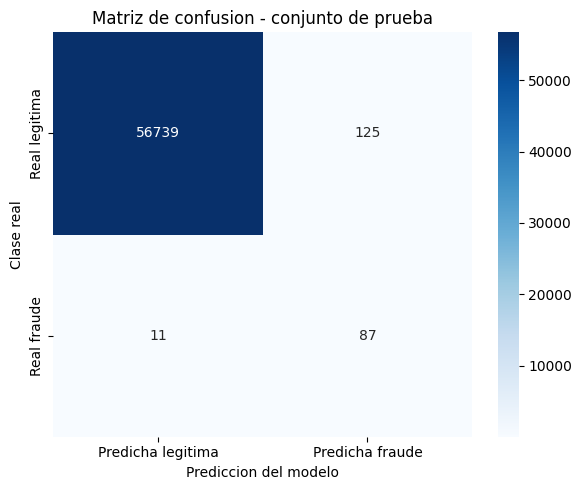

In [ ]:
# Reporte de clasificacion con el umbral seleccionado
test_predictions = (test_probabilities >= SELECTED_THRESHOLD).astype(int)
print(classification_report(
    y_test,
    test_predictions,
    target_names=["Legitima", "Fraude"],
    zero_division=0,
))

cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicha legitima", "Predicha fraude"],
    yticklabels=["Real legitima", "Real fraude"],
)
plt.title("Matriz de confusion - conjunto de prueba")
plt.ylabel("Clase real")
plt.xlabel("Prediccion del modelo")
plt.tight_layout()
plt.show()

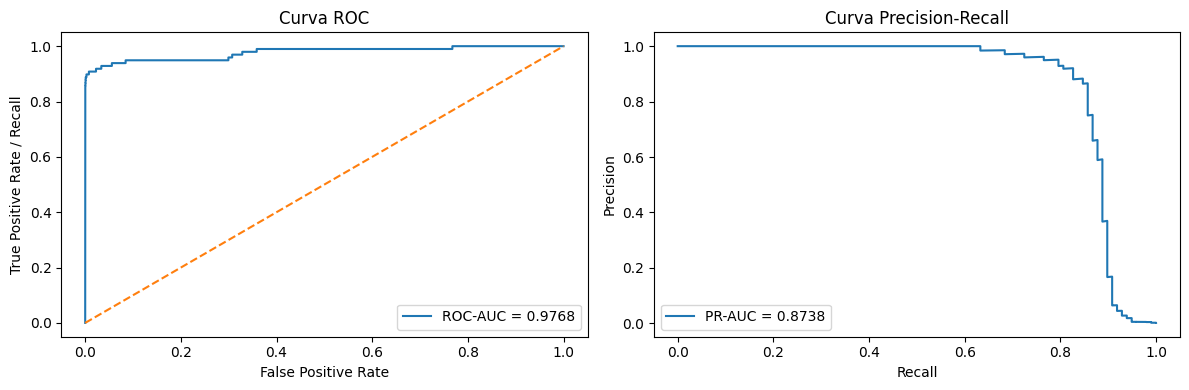

In [ ]:
# Curvas ROC y Precision-Recall
fpr_test, tpr_test, _ = roc_curve(y_test, test_probabilities)
precision_values, recall_values, _ = precision_recall_curve(y_test, test_probabilities)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(fpr_test, tpr_test, label=f"ROC-AUC = {roc_auc:.4f}")
axes[0].plot([0, 1], [0, 1], linestyle="--")
axes[0].set_title("Curva ROC")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate / Recall")
axes[0].legend()

axes[1].plot(recall_values, precision_values, label=f"PR-AUC = {pr_auc:.4f}")
axes[1].set_title("Curva Precision-Recall")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

### Interpretacion de falsos positivos y falsos negativos

- **Falso positivo (FP):** una transaccion legitima que el modelo marca como fraude. Puede bloquear a un cliente real.
- **Falso negativo (FN):** una transaccion fraudulenta que el modelo deja pasar.
- **FPR:** porcentaje de transacciones legitimas que fueron marcadas incorrectamente como fraude.
- **Precision:** porcentaje de las alertas de fraude que realmente eran fraude.
- **Recall:** porcentaje de fraudes reales que el modelo logra detectar.

El FPR y la precision no significan lo mismo. En un dataset muy desbalanceado, un FPR aparentemente bajo puede producir muchas alertas incorrectas. Por eso se revisan en conjunto FPR, precision y recall. El limite de FPR y el recall minimo se aplican durante la seleccion en validacion; el resultado de prueba puede diferir.

## 11. Estimacion del monto fraudulento no detectado

Como el dataset incluye la columna `Amount`, se puede calcular una referencia del monto fraudulento que el modelo no detecto. Esto es solo una aproximacion basada en el dataset: no representa directamente las perdidas reales de PagoSeguro, ni incluye recuperaciones, comisiones u otras condiciones del negocio.

In [ ]:
# Volver a unir las predicciones con los datos de prueba para estimar montos
results_test = X_test.copy()
results_test["real_class"] = y_test
results_test["predicted_class"] = test_predictions
results_test["fraud_probability"] = test_probabilities

actual_fraud_amount = results_test.loc[results_test["real_class"] == 1, "Amount"].sum()
missed_fraud_amount = results_test.loc[
    (results_test["real_class"] == 1) & (results_test["predicted_class"] == 0),
    "Amount",
].sum()

missed_amount_percent = (
    missed_fraud_amount / actual_fraud_amount * 100
    if actual_fraud_amount > 0 else 0
)

print("Monto total de transacciones fraudulentas reales en prueba: {:.2f}".format(actual_fraud_amount))
print("Monto fraudulento no detectado: {:.2f}".format(missed_fraud_amount))
print("Porcentaje del monto fraudulento no detectado: {:.2f}%".format(missed_amount_percent))
print("Nota: estos montos pertenecen al dataset y no deben presentarse como perdidas reales anuales de PagoSeguro.")

Monto total de transacciones fraudulentas reales en prueba: 10644.93
Monto fraudulento no detectado: 1826.50
Porcentaje del monto fraudulento no detectado: 17.16%
Nota: estos montos pertenecen al dataset y no deben presentarse como perdidas reales anuales de PagoSeguro.


## 12. Importancia de variables

,importance
V14,0.447744
V4,0.083338
V10,0.062960
V12,0.061264
Amount,0.026001
V17,0.025053
V20,0.024960
V3,0.022580
V8,0.022523
V13,0.019838


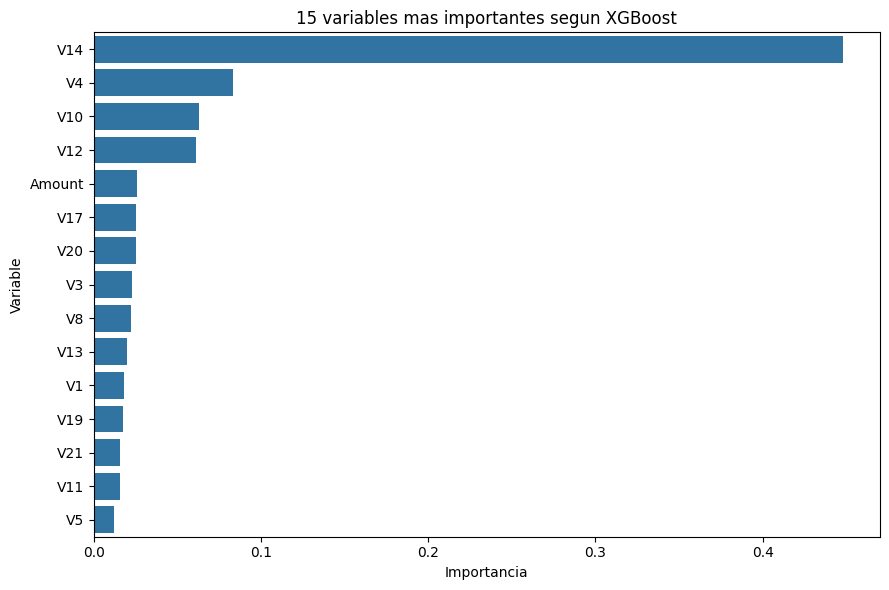

In [ ]:
# Importancia entregada por XGBoost
importance = pd.Series(model.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)

display(importance.head(15).to_frame("importance"))

plt.figure(figsize=(9, 6))
sns.barplot(x=importance.head(15).values, y=importance.head(15).index)
plt.title("15 variables mas importantes segun XGBoost")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

## 13. Explicabilidad del modelo con SHAP

SHAP permite estimar cuanto aporta cada variable a una prediccion. Para evitar un calculo demasiado pesado, se utiliza una muestra de hasta 300 transacciones del conjunto de prueba.

En un sistema real, el reporte explicativo de cada rechazo puede generarse de forma asincrona para no aumentar la latencia de la respuesta de pago.

In [ ]:
# Tomar una muestra para explicar el comportamiento del modelo
shap_sample_size = min(300, len(X_test))
X_shap = X_test.sample(n=shap_sample_size, random_state=RANDOM_STATE)

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_shap)

print("Valores SHAP calculados para", shap_sample_size, "transacciones")

Valores SHAP calculados para 300 transacciones


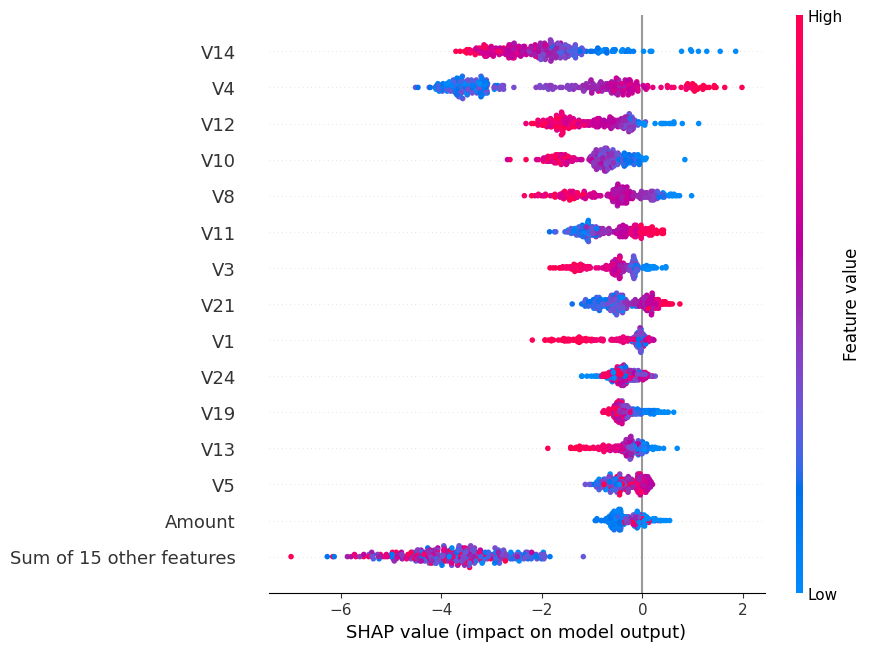

In [ ]:
# Resumen global: variables que mas influyen en las predicciones
try:
    shap.plots.beeswarm(shap_values, max_display=15)
except Exception as e:
    print("No se pudo crear beeswarm con esta version de SHAP:", e)
    raw_shap_values = explainer.shap_values(X_shap)
    if isinstance(raw_shap_values, list):
        raw_shap_values = raw_shap_values[-1]
    shap.summary_plot(raw_shap_values, X_shap, max_display=15)

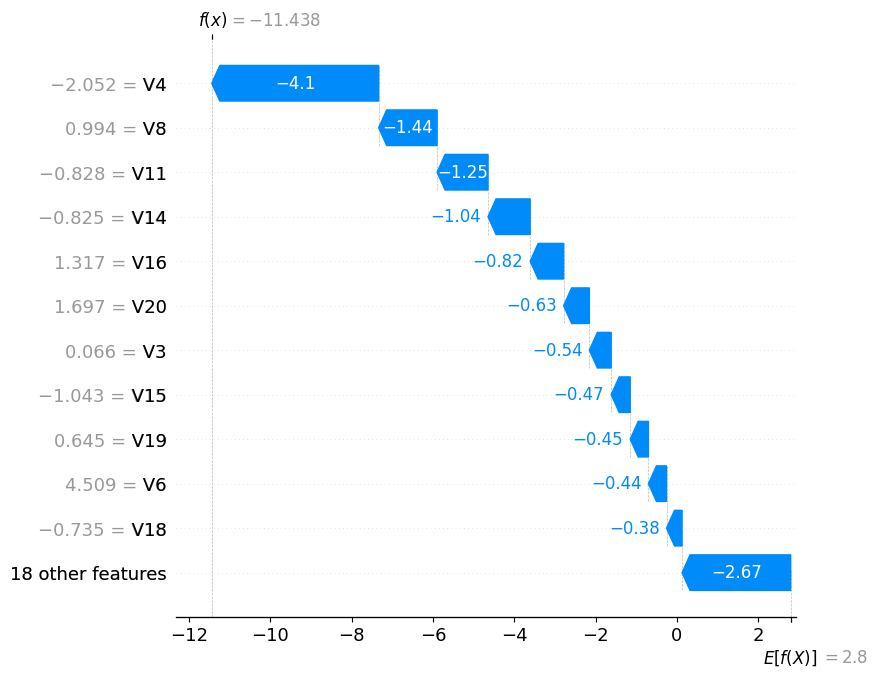

In [ ]:
# Explicacion local de una transaccion de ejemplo
try:
    shap.plots.waterfall(shap_values[0], max_display=12)
except Exception as e:
    print("No se pudo crear waterfall con esta version de SHAP:", e)
    raw_shap_values = explainer.shap_values(X_shap)
    if isinstance(raw_shap_values, list):
        raw_shap_values = raw_shap_values[-1]
    shap.force_plot(
        explainer.expected_value,
        raw_shap_values[0],
        X_shap.iloc[0],
        matplotlib=True,
    )

## 14. Funcion para probar una transaccion

La funcion recibe un diccionario con las mismas variables usadas durante el entrenamiento. Devuelve la probabilidad estimada y una decision de ejemplo. En el sistema final, las reglas de autorizacion deben ser revisadas por PagoSeguro y no depender solo de este notebook.

In [ ]:
def predict_transaction(transaction_data, model=model, threshold=SELECTED_THRESHOLD):
    """Predice el riesgo de fraude usando el modelo y la calibracion seleccionada."""
    if not isinstance(transaction_data, dict):
        raise TypeError("transaction_data debe ser un diccionario")

    missing_features = [feature for feature in FEATURE_NAMES if feature not in transaction_data]
    if missing_features:
        raise ValueError(f"Faltan variables requeridas: {missing_features}")

    row = pd.DataFrame(
        [[transaction_data[feature] for feature in FEATURE_NAMES]],
        columns=FEATURE_NAMES,
    )

    if row.isnull().any().any():
        raise ValueError("La transaccion contiene valores nulos")

    raw_probability = float(model.predict_proba(row)[0, 1])
    probability = float(calibrate_probabilities([raw_probability])[0])
    prediction = int(probability >= threshold)

    return {
        "fraud_probability": probability,
        "raw_fraud_probability": raw_probability,
        "predicted_class": prediction,
        "decision": "REVISAR_O_RECHAZAR" if prediction == 1 else "AUTORIZAR",
        "threshold": float(threshold),
    }

# Prueba con una fila real del conjunto de prueba (solo como demostracion)
example_transaction = X_test.iloc[0].to_dict()
example_result = predict_transaction(example_transaction)
print(json.dumps(example_result, indent=4, ensure_ascii=False))

{
    "fraud_probability": 3.506277096431279e-05,
    "raw_fraud_probability": 3.1061833851708798e-06,
    "predicted_class": 0,
    "decision": "AUTORIZAR",
    "threshold": 0.013333670641917874
}


## 15. Guardado del modelo y sus metadatos

Se guardan los siguientes archivos:

- `xgboost_fraud_model.json`: modelo en formato nativo de XGBoost.
- `xgboost_fraud_model.joblib`: objeto de Python para facilitar su carga desde otro servicio.
- `calibration_model.joblib`: calibrador sigmoid; puede contener `None` si no mejoro la calibracion.
- `model_metadata.json`: umbral, variables, hiperparametros, criterios y metricas.
- `test_metrics.csv`: comparacion de resultados en prueba.

La API posterior debe cargar tanto el modelo como el calibrador y usar el umbral guardado en los metadatos.

In [ ]:
# Guardar modelo en formato nativo XGBoost
model_json_path = ARTIFACT_DIR / "xgboost_fraud_model.json"
model.save_model(model_json_path)

# Guardar objeto completo para usarlo desde Python
model_joblib_path = ARTIFACT_DIR / "xgboost_fraud_model.joblib"
joblib.dump(model, model_joblib_path)

# Guardar calibrador de probabilidades
calibration_path = ARTIFACT_DIR / "calibration_model.joblib"
joblib.dump(calibrator, calibration_path)

# Guardar informacion necesaria para inferencia
metadata = {
    "project": "PagoSeguro - Deteccion de Fraude",
    "case": "Caso 3",
    "model_type": "XGBClassifier",
    "xgboost_version": xgb.__version__,
    "threshold": float(SELECTED_THRESHOLD),
    "max_recall_threshold": float(MAX_RECALL_THRESHOLD),
    "threshold_objective": "Maximizar F0.5 sujeto a FPR <= 5% y recall >= 80% cuando sea posible",
    "max_fpr_validation": MAX_FPR,
    "min_recall_validation": MIN_RECALL,
    "f_beta": F_BETA,
    "calibration_method": "Platt scaling con LogisticRegression" if calibrator is not None else "Probabilidad original de XGBoost",
    "brier_raw_validation": float(brier_raw_validation),
    "brier_final_validation": float(brier_final_validation),
    "features": FEATURE_NAMES,
    "target_column": "Class",
    "target_definition": {"0": "Legitima", "1": "Fraude"},
    "hyperparameters": model.get_params(),
    "test_metrics_threshold_selected": {
        key: (float(value) if isinstance(value, (np.floating, np.integer)) else value)
        for key, value in test_selected_metrics.items()
    },
    "test_roc_auc": float(roc_auc),
    "test_pr_auc": float(pr_auc),
}

metadata_path = ARTIFACT_DIR / "model_metadata.json"
with open(metadata_path, "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=4, ensure_ascii=False, default=str)

# Guardar metricas en CSV para incluirlas en el informe
metrics_path = ARTIFACT_DIR / "test_metrics.csv"
test_metrics_df.to_csv(metrics_path, index=True)

print("Archivos guardados:")
for file_path in [model_json_path, model_joblib_path, calibration_path, metadata_path, metrics_path]:
    print("-", file_path.resolve())

Archivos guardados:
- /content/artifacts/xgboost_fraud_model.json
- /content/artifacts/xgboost_fraud_model.joblib
- /content/artifacts/calibration_model.joblib
- /content/artifacts/model_metadata.json
- /content/artifacts/test_metrics.csv


## 16. Comprobar que el modelo guardado se puede cargar

In [ ]:
loaded_model = joblib.load(model_joblib_path)
loaded_calibrator = joblib.load(calibration_path)
loaded_raw_probability = float(loaded_model.predict_proba(X_test.iloc[[0]])[0, 1])

if loaded_calibrator is None:
    loaded_probability = loaded_raw_probability
else:
    loaded_probability = float(loaded_calibrator.predict_proba(
        probabilities_to_logit([loaded_raw_probability])
    )[0, 1])

original_probability = float(calibrate_probabilities(
    model.predict_proba(X_test.iloc[[0]])[:, 1]
)[0])

print("Probabilidad modelo cargado y calibrado:", loaded_probability)
print("Probabilidad modelo original y calibrado:", original_probability)
print("Diferencia:", abs(loaded_probability - original_probability))

assert np.isclose(loaded_probability, original_probability), "El modelo o calibrador cargado no coincide con el original"
print("Verificacion correcta: modelo y calibrador se guardaron y cargaron correctamente")

Probabilidad modelo cargado y calibrado: 3.506277096431279e-05
Probabilidad modelo original y calibrado: 3.506277096431279e-05
Diferencia: 0.0
Verificacion correcta: modelo y calibrador se guardaron y cargaron correctamente


## 17. Resumen de resultados para el informe EP3

La siguiente tabla muestra los resultados obtenidos en el conjunto de prueba con el umbral optimizado. Tambien se muestra la comparacion de umbrales. Las metricas se completan automaticamente al ejecutar el notebook.

No afirmar que se cumple el objetivo empresarial completo solo por obtener un FPR menor a 5%. Tambien se debe revisar precision, costos de falsos positivos, datos reales de PagoSeguro y funcionamiento del flujo completo.

In [ ]:
summary = {
    "Umbral optimizado": SELECTED_THRESHOLD,
    "Accuracy": test_selected_metrics["accuracy"],
    "Precision fraude": test_selected_metrics["precision"],
    "Recall fraude": test_selected_metrics["recall"],
    "F1-score fraude": test_selected_metrics["f1_score"],
    "FPR": test_selected_metrics["fpr"],
    "FNR": test_selected_metrics["fnr"],
    "ROC-AUC": roc_auc,
    "PR-AUC": pr_auc,
    "Falsos positivos": test_selected_metrics["fp"],
    "Falsos negativos": test_selected_metrics["fn"],
}

summary_df = pd.DataFrame({"Metrica": list(summary.keys()), "Resultado": list(summary.values())})
display(summary_df)

print("\\nComparacion de estrategias de umbral:")
display(test_metrics_df[["threshold", "precision", "recall", "fpr", "f1_score", "fp", "fn"]])

print("\\nLectura automatica:")
if test_selected_metrics["fpr"] <= MAX_FPR:
    print("El FPR de prueba quedo dentro del objetivo experimental de 5%.")
else:
    print("El FPR de prueba supero el 5%; revisar generalizacion del modelo.")

if test_selected_metrics["recall"] >= MIN_RECALL:
    print("El recall de prueba fue igual o superior al minimo experimental de 80%.")
else:
    print("El recall de prueba quedo bajo el minimo experimental de 80%.")

print("Precision: de todas las transacciones marcadas como fraude, {:.2f}% eran fraude.".format(
    test_selected_metrics["precision"] * 100
))
print("Recall: se detecto {:.2f}% de los fraudes del conjunto de prueba.".format(
    test_selected_metrics["recall"] * 100
))
print("El modelo, calibrador y metadatos quedaron guardados en:", ARTIFACT_DIR.resolve())

,Metrica,Resultado
0,Umbral optimizado,0.013334
1,Accuracy,0.997612
2,Precision fraude,0.410377
3,Recall fraude,0.887755
4,F1-score fraude,0.561290
5,FPR,0.002198
6,FNR,0.112245
7,ROC-AUC,0.976818
8,PR-AUC,0.873798
9,Falsos positivos,125.000000


\nComparacion de estrategias de umbral:


,threshold,precision,recall,fpr,f1_score,fp,fn
Umbral 0.50,0.500000,0.939759,0.795918,0.000088,0.861878,5,20
Maximo recall con FPR <= 5%,0.001859,0.063830,0.918367,0.023213,0.119363,1320,8
Umbral optimizado F0.5,0.013334,0.410377,0.887755,0.002198,0.561290,125,11


\nLectura automatica:
El FPR de prueba quedo dentro del objetivo experimental de 5%.
El recall de prueba fue igual o superior al minimo experimental de 80%.
Precision: de todas las transacciones marcadas como fraude, 41.04% eran fraude.
Recall: se detecto 88.78% de los fraudes del conjunto de prueba.
El modelo, calibrador y metadatos quedaron guardados en: /content/artifacts


## 18. Limitaciones y siguientes pasos

1. El dataset es publico y no representa necesariamente el comportamiento real de los clientes de PagoSeguro.
2. Las variables `V1` a `V28` estan anonimizadas, por lo que no tienen una interpretacion directa para el negocio.
3. La separacion usada es estratificada y aleatoria. Para una validacion productiva conviene complementar con pruebas temporales y datos nuevos.
4. La seleccion de umbral aplica un limite de FPR y un recall minimo experimental. PagoSeguro debe definir los costos reales de bloquear clientes y dejar pasar fraude.
5. La calibracion sigmoid se ajusta con una muestra separada. En produccion debe revisarse con datos recientes y recalibrarse cuando cambie el comportamiento de las transacciones.
6. La latencia, el throughput, la disponibilidad y el costo de AWS no se miden en este notebook; deben evaluarse durante el despliegue y las pruebas de carga.
7. SHAP explica la salida del modelo XGBoost base. La calibracion sigmoid transforma su probabilidad despues de esa prediccion.
8. El notebook no constituye por si solo un sistema productivo: faltan API REST, autenticacion, mensajeria, dashboard, monitoreo y despliegue en SageMaker.

### Evaluación y optimización del modelo XGBoost

El modelo XGBoost fue entrenado utilizando el dataset Credit Card Fraud Detection de Kaggle. Durante su evaluación se realizaron pruebas con distintos umbrales de clasificación para encontrar un equilibrio entre la detección de fraudes y la reducción de falsas alarmas.

Inicialmente se utilizó un umbral tradicional de 0.50. Sin embargo, este valor generaba un Recall de 79,59%, por lo que se realizó una optimización utilizando la métrica F0.5, dando mayor importancia a la Precision.

El umbral optimizado fue de 0.013334, obteniendo un Accuracy de 99,76%, Precision de 41,04%, Recall de 88,78% y F1-score de 56,13%. Además, se obtuvo un ROC-AUC de 97,68% y un PR-AUC de 87,38%.

En cuanto a las predicciones, el modelo generó 125 falsos positivos y 11 falsos negativos. La tasa de falsos positivos (FPR) fue de 0,22%, manteniéndose por debajo del límite experimental establecido del 5%.

Los resultados muestran una mejora en la detección de transacciones fraudulentas respecto al umbral tradicional. Sin embargo, la Precision todavía representa una oportunidad de mejora, ya que no todas las transacciones identificadas como sospechosas corresponden realmente a un fraude.

Finalmente, se seleccionó el umbral optimizado como configuración experimental para continuar con la integración del modelo en la arquitectura de PagoSeguro.

In [ ]:
from pathlib import Path
from zipfile import ZipFile
from google.colab import files

artifacts = Path("/content/artifacts")

required = [
    "xgboost_fraud_model.json",
    "calibration_model.joblib",
    "model_metadata.json"
]

# Comprobar que existan todos los archivos
for name in required:
    if not (artifacts / name).exists():
        raise FileNotFoundError(f"No se encontro: {name}")

# Crear archivo ZIP
zip_path = Path("/content/PagoSeguro_artifacts.zip")

with ZipFile(zip_path, "w") as zip_file:
    for name in required:
        zip_file.write(artifacts / name, arcname=name)

print("Artefactos preparados correctamente")

files.download(str(zip_path))

Artefactos preparados correctamente


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import json
import numpy as np

# Buscar una transaccion legitima correctamente identificada
legit_indices = np.where(
    (np.asarray(y_test) == 0) & (test_predictions == 0)
)[0]

# Buscar un fraude correctamente detectado
fraud_indices = np.where(
    (np.asarray(y_test) == 1) & (test_predictions == 1)
)[0]

if len(legit_indices) == 0 or len(fraud_indices) == 0:
    raise ValueError("No se encontraron ejemplos suficientes")

# Seleccionar ejemplos de prueba
legit_idx = legit_indices[0]
fraud_idx = fraud_indices[0]

def crear_payload(idx, transaction_id):
    features = X_test.iloc[idx].to_dict()

    return {
        "transaction_id": transaction_id,
        "features": {
            key: float(value)
            for key, value in features.items()
        }
    }

# Crear ambas solicitudes
transaccion_normal = crear_payload(legit_idx, "TX-LEGITIMA-001")
transaccion_fraude = crear_payload(fraud_idx, "TX-FRAUDE-001")

print("TRANSACCION LEGITIMA:")
print(json.dumps(transaccion_normal, indent=4))

print("\nTRANSACCION FRAUDULENTA:")
print(json.dumps(transaccion_fraude, indent=4))

TRANSACCION LEGITIMA:
{
    "transaction_id": "TX-LEGITIMA-001",
    "features": {
        "V1": -0.674466064578314,
        "V2": 1.40810501967799,
        "V3": -1.11062205357093,
        "V4": -1.32836577843066,
        "V5": 1.38899603254837,
        "V6": -1.30843906707795,
        "V7": 1.88587890268717,
        "V8": -0.614232966299775,
        "V9": 0.311652212453101,
        "V10": 0.65075700363522,
        "V11": -0.857784661547805,
        "V12": -0.229961445775592,
        "V13": -0.19981700479103,
        "V14": 0.266371326329879,
        "V15": -0.0465441684754424,
        "V16": -0.741398089749789,
        "V17": -0.605616644106022,
        "V18": -0.39256818789208,
        "V19": -0.162648311024695,
        "V20": 0.394321820843914,
        "V21": 0.0800842396026648,
        "V22": 0.810033595602455,
        "V23": -0.224327230436412,
        "V24": 0.707899237446867,
        "V25": -0.13583702273753,
        "V26": 0.0451021964988772,
        "V27": 0.533837219064273,
